# Validate Lichess Puzzles and Extract Initial Features

First review five examples, then validate the official move sequences in chunks. The raw CSV stays unchanged. Each FEN describes the board **before the initiating opponent move**; features are measured after that first move.

This notebook checks board validity and legality of the official sequence. It does **not** prove that the reference moves are optimal or uniquely correct. No LLM calls or sampling are performed.

Use the project `.venv` kernel and run cells in order. The full database has over six million puzzles, so full validation may take considerable time.

Historical outputs from the completed October 13 data preparation are retained. Only repository-path discovery was adapted for this notebook folder. Rerun inspection if needed; rerun full validation only if the source data or validation method changes. The byte-exact original notebook is preserved in `archive/pre_first_move_code.zip`.

## 1. Imports, paths, and run settings
Use `ROW_LIMIT = 10_000` for a quick check. Set it to `None` to validate the complete dataset. Outputs from limited runs are clearly marked as partial. The notebook keeps separate files for full and partial runs.

In [1]:
# Load chess validation and table libraries.
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
import csv
import hashlib
import json
import time

import chess
import pandas as pd
from IPython.display import display

# Find the repository whether the notebook starts in the root or code folder.
project_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/lichess_db_puzzle.csv.zst").is_file())
source_path = project_root / "data" / "lichess_db_puzzle.csv.zst"
assert source_path.is_file(), f"Dataset not found: {source_path}"

# Change only this setting to switch between a pilot and the complete scan.
ROW_LIMIT = None
CHUNK_SIZE = 10_000
run_label = "full" if ROW_LIMIT is None else f"first_{ROW_LIMIT}"
output_dir = project_root / "data" / "validation" / run_label
output_dir.mkdir(parents=True, exist_ok=True)
print("Run:", run_label)
print("Output folder:", output_dir)

Run: full
Output folder: E:\DA_401\LLM_Chess_Comparison\data\validation\full


## 2. Define the chess checks and features

For each puzzle:
1. Parse the original FEN and require a valid standard-chess position.
2. Apply each official move only if it is legal in the current position.
3. After move 1, record the solver's board and initial-position features.
4. Count required solver moves from indices 1, 3, 5, and so on.

Material values are pawn = 1, knight = 3, bishop = 3, rook = 5, queen = 9, and king = 0. Material balance is **solver material minus opponent material**.

Game phase is not inferred here. We preserve Lichess phase labels in `Themes` and can choose a phase definition later. Rating uncertainty and number of plays are retained without imposing quality filters.

In [2]:
# Keep errors distinct so exclusions can be documented and reviewed.
def validate_puzzle(puzzle):
    try:
        board = chess.Board(puzzle["FEN"])
    except ValueError as error:
        return None, {"reason": "unparseable_fen", "detail": str(error)}

    if not board.is_valid():
        return None, {"reason": "invalid_board", "detail": str(board.status())}

    moves = puzzle["Moves"].split()
    if len(moves) < 2:
        return None, {"reason": "too_few_moves", "detail": "No solver move follows the initiating move"}

    # Replay the whole official sequence and measure features after move 1.
    features = None
    for move_index, move_text in enumerate(moves):
        try:
            move = chess.Move.from_uci(move_text)
        except ValueError as error:
            return None, {"reason": "invalid_uci", "detail": str(error),
                          "move_index": move_index, "move": move_text}

        if move not in board.legal_moves:
            return None, {"reason": "illegal_move", "detail": board.fen(),
                          "move_index": move_index, "move": move_text}
        board.push(move)

        if move_index == 0:
            solver = board.turn
            values = {chess.PAWN: 1, chess.KNIGHT: 3, chess.BISHOP: 3,
                      chess.ROOK: 5, chess.QUEEN: 9, chess.KING: 0}
            material = sum(value * (len(board.pieces(piece, solver))
                                   - len(board.pieces(piece, not solver)))
                           for piece, value in values.items())
            features = {
                "puzzle_id": puzzle["PuzzleId"],
                "solver_fen": board.fen(),
                "solver_side": "white" if solver else "black",
                "total_solver_moves": len(moves[1::2]),
                "legal_moves": board.legal_moves.count(),
                "piece_count": len(board.piece_map()),
                "material_balance": material,
                "puzzle_rating": puzzle["Rating"],
                "rating_deviation": puzzle["RatingDeviation"],
                "nb_plays": puzzle["NbPlays"],
                "themes": puzzle["Themes"],
            }

    return features, None

## 3. Verify the logic with known test positions
These fixtures are checks of the code, not empirical research results. Check a valid sequence, material perspective, solver move count, illegal moves, malformed moves, and invalid FENs.

In [3]:
# Construct a known starting-position fixture, separate from the research data.
fixture = {"PuzzleId": "test_only", "FEN": chess.STARTING_FEN,
           "Moves": "e2e4 e7e5 g1f3 b8c6", "Rating": "1000",
           "RatingDeviation": "80", "NbPlays": "100", "Themes": ""}
features, failure = validate_puzzle(fixture)
assert failure is None
assert features["solver_side"] == "black"
assert features["total_solver_moves"] == 2
assert features["piece_count"] == 32
assert features["legal_moves"] == 20
assert features["material_balance"] == 0
expected_board = chess.Board()
expected_board.push_uci("e2e4")
assert features["solver_fen"] == expected_board.fen()

# After a pawn capture, the solving side is one pawn behind.
capture_board = chess.Board()
for move in ["e2e4", "d7d5"]:
    capture_board.push_uci(move)
capture_fixture = dict(fixture, FEN=capture_board.fen(), Moves="e4d5 d8d5")
features, failure = validate_puzzle(capture_fixture)
assert failure is None and features["material_balance"] == -1

# Check later illegal moves and malformed inputs are rejected with clear reasons.
assert validate_puzzle(dict(fixture, Moves="e2e4 e7e4"))[1]["reason"] == "illegal_move"
assert validate_puzzle(dict(fixture, Moves="e2e4 nonsense"))[1]["reason"] == "invalid_uci"
assert validate_puzzle(dict(fixture, FEN="not a FEN"))[1]["reason"] == "unparseable_fen"
assert validate_puzzle(dict(fixture, FEN="8/8/8/8/8/8/8/8 w - - 0 1"))[1]["reason"] == "invalid_board"
assert validate_puzzle(dict(fixture, Moves="e2e4"))[1]["reason"] == "too_few_moves"
print("All reconstruction and feature checks passed.")

All reconstruction and feature checks passed.


## 4. Review five actual puzzles
Display the original board and the actual solver board. These first five records are examples, not a representative sample.

Puzzle: 00008 | Official sequence: f2g3 e6e7 b2b1 b3c1 b1c1 h6c1
Original board (before opponent move):


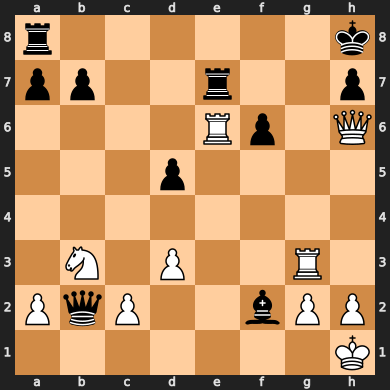

Solver board (after opponent move):


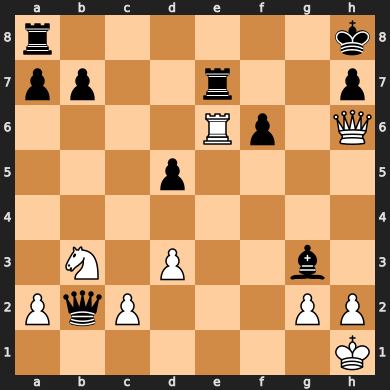

,puzzle_id,solver_side,total_solver_moves,legal_moves,piece_count,material_balance,puzzle_rating,rating_deviation,nb_plays,themes
0,00008,white,3,39,19,-5,1811,76,10282,crushing hangingPiece long middlegame


Puzzle: 0000D | Official sequence: d3d6 f8d8 d6d8 f6d8
Original board (before opponent move):


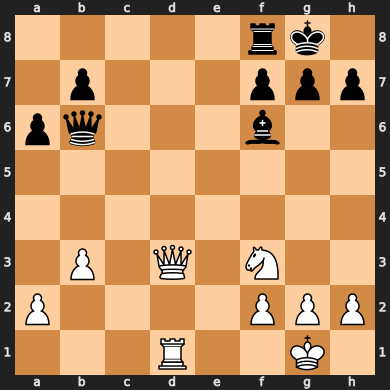

Solver board (after opponent move):


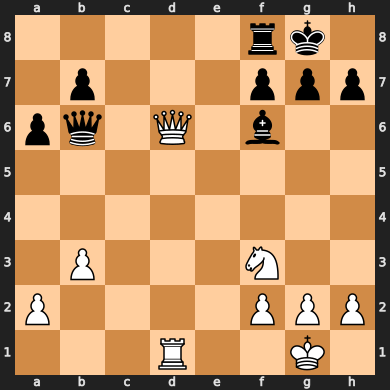

,puzzle_id,solver_side,total_solver_moves,legal_moves,piece_count,material_balance,puzzle_rating,rating_deviation,nb_plays,themes
0,0000D,black,2,33,18,0,1529,74,37506,advantage endgame short


Puzzle: 0000H | Official sequence: d1h5 d5g2
Original board (before opponent move):


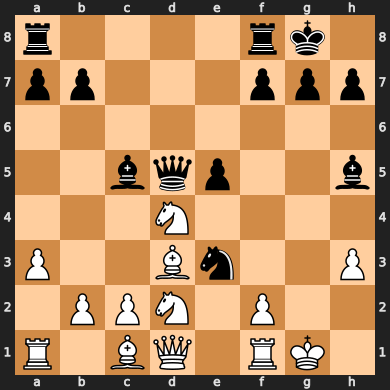

Solver board (after opponent move):


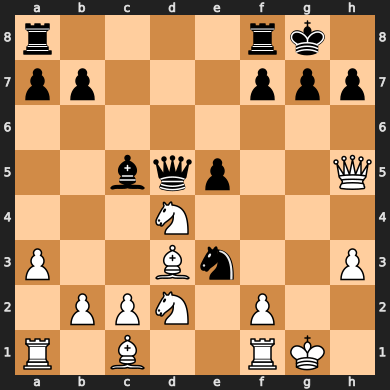

,puzzle_id,solver_side,total_solver_moves,legal_moves,piece_count,material_balance,puzzle_rating,rating_deviation,nb_plays,themes
0,0000H,black,1,46,25,-5,1554,223,11,mate mateIn1 middlegame oneMove


Puzzle: 0008Q | Official sequence: e7f7 f5e5 e2f1 e5e6
Original board (before opponent move):


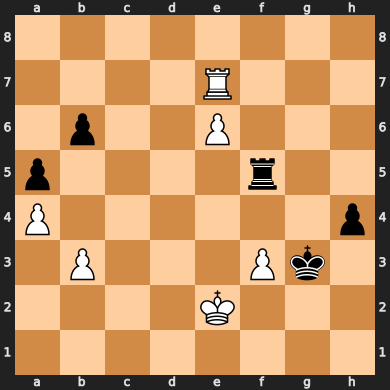

Solver board (after opponent move):


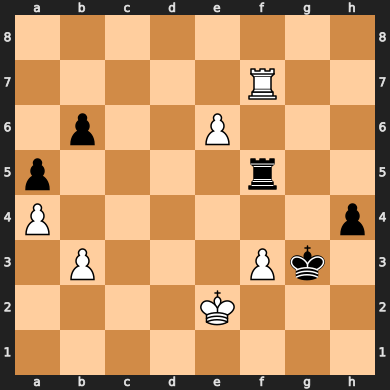

,puzzle_id,solver_side,total_solver_moves,legal_moves,piece_count,material_balance,puzzle_rating,rating_deviation,nb_plays,themes
0,0008Q,black,2,16,11,-1,1383,81,771,advantage endgame rookEndgame short


Puzzle: 0009B | Official sequence: b6c5 e2g4 h3g4 d1g4
Original board (before opponent move):


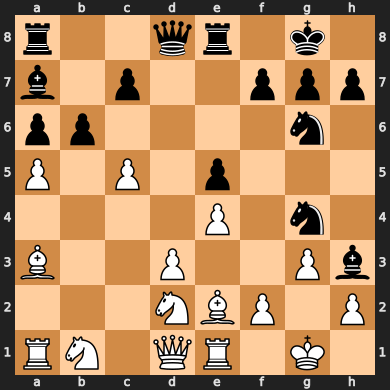

Solver board (after opponent move):


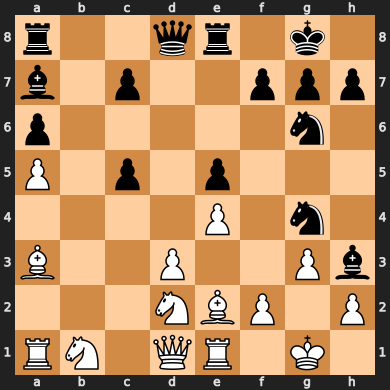

,puzzle_id,solver_side,total_solver_moves,legal_moves,piece_count,material_balance,puzzle_rating,rating_deviation,nb_plays,themes
0,0009B,white,2,22,29,-1,1084,74,611,advantage middlegame short


In [4]:
# Read five examples from the original source.
examples = pd.read_csv(source_path, compression="zstd", nrows=5,
                       dtype=str, keep_default_na=False)
for puzzle in examples.to_dict("records"):
    features, failure = validate_puzzle(puzzle)
    print("Puzzle:", puzzle["PuzzleId"], "| Official sequence:", puzzle["Moves"])
    if failure:
        print("Validation failure:", failure)
        continue
    print("Original board (before opponent move):")
    display(chess.Board(puzzle["FEN"]))
    print("Solver board (after opponent move):")
    display(chess.Board(features["solver_fen"]))
    display(pd.DataFrame([features]).drop(columns=["solver_fen"]))

## 5. Validate records and save features incrementally

Write valid puzzles to `validated_features.csv` and failures with their original FEN and solution to `failures.csv`. These are derived files under the ignored `data/` folder. Files for the selected run label are overwritten when this cell is rerun; the raw source and other run labels are preserved.

The first 10,000 rows are a technical pilot, not a stratified research sample. Duplicate IDs and numeric parsing were checked separately in the inspection notebook. No quality thresholds are applied here.

In [5]:
# Hash this exact source snapshot for traceability.
checksum = hashlib.sha256()
with source_path.open("rb") as source:
    for block in iter(lambda: source.read(1024 * 1024), b""):
        checksum.update(block)

# Prepare output columns and counters for this run.
feature_columns = ["puzzle_id", "solver_fen", "solver_side", "total_solver_moves",
                   "legal_moves", "piece_count", "material_balance", "puzzle_rating",
                   "rating_deviation", "nb_plays", "themes"]
failure_columns = ["puzzle_id", "fen", "moves", "reason", "detail", "move_index", "move"]
processed = valid = 0
failure_counts = Counter()
started = time.perf_counter()

# Process small chunks; CSV writers save each result without holding all boards in memory.
with (output_dir / "validated_features.csv").open("w", newline="", encoding="utf-8") as good_file,      (output_dir / "failures.csv").open("w", newline="", encoding="utf-8") as bad_file:
    good_writer = csv.DictWriter(good_file, fieldnames=feature_columns)
    bad_writer = csv.DictWriter(bad_file, fieldnames=failure_columns)
    good_writer.writeheader()
    bad_writer.writeheader()

    chunks = pd.read_csv(source_path, compression="zstd", dtype=str,
                         keep_default_na=False, chunksize=CHUNK_SIZE, nrows=ROW_LIMIT)
    for chunk in chunks:
        for puzzle in chunk.to_dict("records"):
            features, failure = validate_puzzle(puzzle)
            processed += 1
            if failure is None:
                good_writer.writerow(features)
                valid += 1
            else:
                failure_counts[failure["reason"]] += 1
                bad_writer.writerow({"puzzle_id": puzzle["PuzzleId"], "fen": puzzle["FEN"],
                                     "moves": puzzle["Moves"], **failure})
        good_file.flush()
        bad_file.flush()
        elapsed = time.perf_counter() - started
        print(f"Checked {processed:,} | Valid {valid:,} | Failures {processed - valid:,} | {elapsed:.1f} seconds")

# Save counts, definitions, and run scope after successful completion.
summary = {
    "source": str(source_path.resolve()), "sha256": checksum.hexdigest(),
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "row_limit": ROW_LIMIT, "scope": "full_dataset" if ROW_LIMIT is None else "first_rows_pilot",
    "processed": processed, "valid": valid, "failed": processed - valid,
    "failure_counts": dict(failure_counts),
    "elapsed_seconds": round(time.perf_counter() - started, 2),
    "material_values": {"pawn": 1, "knight": 3, "bishop": 3, "rook": 5, "queen": 9, "king": 0},
    "material_perspective": "solver minus opponent",
    "feature_position": "after the first official move",
    "notes": ["Legal official sequence does not establish optimality or uniqueness.",
              "No rating-quality filters or sampling applied."]
}
(output_dir / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
assert processed == valid + sum(failure_counts.values())
print("Saved validation files to:", output_dir)
display(pd.DataFrame([summary]).drop(columns=["notes", "material_values"]))

Checked 10,000 | Valid 10,000 | Failures 0 | 1.4 seconds


Checked 20,000 | Valid 20,000 | Failures 0 | 2.8 seconds


Checked 30,000 | Valid 30,000 | Failures 0 | 4.2 seconds


Checked 40,000 | Valid 40,000 | Failures 0 | 5.6 seconds


Checked 50,000 | Valid 50,000 | Failures 0 | 7.0 seconds


...

Checked 6,130,000 | Valid 6,130,000 | Failures 0 | 976.4 seconds


Checked 6,140,000 | Valid 6,140,000 | Failures 0 | 978.0 seconds


Checked 6,150,000 | Valid 6,150,000 | Failures 0 | 979.7 seconds


Checked 6,157,341 | Valid 6,157,341 | Failures 0 | 980.8 seconds
Saved validation files to: E:\DA_401\LLM_Chess_Comparison\data\validation\full


,source,sha256,timestamp_utc,row_limit,scope,processed,valid,failed,failure_counts,elapsed_seconds,material_perspective,feature_position
0,E:\DA_401\LLM_Chess_Comparison\data\lichess_db...,76335bfa7d7c4a7f93c1366d81549e53951ebb79dd43d3...,2026-10-14T03:48:34.608845+00:00,None,full_dataset,6157341,6157341,0,{},980.8,solver minus opponent,after the first official move


## 6. Inspect the saved features and any exclusions
Load small previews rather than the complete output. Do not generalize from a partial pilot to the full database.

In [6]:
# Preview the actual saved features and failed records.
feature_preview = pd.read_csv(output_dir / "validated_features.csv", nrows=5,
                              dtype={"puzzle_id": str})
display(feature_preview)
failed_preview = pd.read_csv(output_dir / "failures.csv", nrows=10,
                             dtype={"puzzle_id": str})
if failed_preview.empty:
    print("No failures in this run.")
else:
    display(failed_preview)

# Estimate full-run time from the pilot; this is only a planning estimate.
if ROW_LIMIT is not None and processed:
    audit_path = project_root / "data" / "inspection" / "notebook_audit.json"
    if audit_path.is_file():
        total_rows = json.loads(audit_path.read_text(encoding="utf-8"))["rows"]
        estimated_minutes = summary["elapsed_seconds"] * total_rows / processed / 60
        print(f"Estimated full-scan runtime at this speed: {estimated_minutes:.1f} minutes")

,puzzle_id,solver_fen,solver_side,total_solver_moves,legal_moves,piece_count,material_balance,puzzle_rating,rating_deviation,nb_plays,themes
0,00008,r6k/pp2r2p/4Rp1Q/3p4/8/1N1P2b1/PqP3PP/7K w - -...,white,3,39,19,-5,1811,76,10282,crushing hangingPiece long middlegame
1,0000D,5rk1/1p3ppp/pq1Q1b2/8/8/1P3N2/P4PPP/3R2K1 b - ...,black,2,33,18,0,1529,74,37506,advantage endgame short
2,0000H,r4rk1/pp3ppp/8/2bqp2Q/3N4/P2Bn2P/1PPN1P2/R1B2R...,black,1,46,25,-5,1554,223,11,mate mateIn1 middlegame oneMove
3,0008Q,8/5R2/1p2P3/p4r2/P6p/1P3Pk1/4K3/8 b - - 2 64,black,2,16,11,-1,1383,81,771,advantage endgame rookEndgame short
4,0009B,r2qr1k1/b1p2ppp/p5n1/P1p1p3/4P1n1/B2P2Pb/3NBP1...,white,2,22,29,-1,1084,74,611,advantage middlegame short


No failures in this run.


## Next steps

After reviewing the pilot, change `ROW_LIMIT` to `None` and rerun all cells for complete validation. Review failures before excluding records. Define rating-quality filters and game phase, then create a reproducible stratified sample of 200?300 valid puzzles.

Keep rating continuous for regression. Sampling strata describe the selected population; a balanced sample does not represent the natural puzzle-frequency distribution.